# ML-11 — Search Intelligence Capstone

**Lane:** Refresh / Content Opportunity Scoring  
**Decision:** Which eligible items should an editor inspect first for a possible refresh?

This notebook mirrors the deployed paper and reruns the model-versus-rule comparison on the repository starter extract. It reports a trailing-window proxy and fixed client-held-out split; it does not claim future prediction or causal refresh impact.

[Open the deployed paper](https://fiona-ali.github.io/flyrank-capstone.html).

## 1. Question
Can nine pre-decision metadata fields rank the review queue better than the transparent Week-4 rule when both are evaluated on the same held-out clients? Output supports human triage only; it does not command an edit, removal, or publication.

## 2. Data
The 30,000-row, 44-column anonymized repository starter CSV has 32 pseudonymous client groups and one row per content item. Aggregates are trailing-window measures; trend_direction compares the latest 30 days with the preceding 30. The export has no calendar timestamp, so exact date coverage is unavailable. This analysis does not claim to scan the full hosted warehouse. Eligibility is impressions_90d >= 100 (22,006 rows). IDs are used only for grouping; model features exclude IDs, target-derived fields, and performance windows.

## 3. Methodology
The target is trend_direction == down, a trailing comparison proxy, not a future outcome. Logistic Regression uses seven numeric and two categorical content metadata fields; numeric fields are median-imputed with missingness indicators and standardized, and categories use an explicit missing value and one-hot encoding. GroupShuffleSplit with test_size 0.25 and seed 42 holds out whole clients: 22 training and 8 test clients, no overlap. The Week-4 comparator is log1p(impressions_90d) × min(days_since_last_update, 180) / 180; its 90-day impressions overlap the target windows, so it is a historical comparator and not leakage-safe prospectively.

## 4. Results and rerun
Run top-to-bottom from the repository or in Colab. The code rebuilds the grouped split, trains both rankings, checks the result against the Week-7 receipt, and writes aggregate metrics and an SVG chart without printing identifiers.

PASS: client groups are disjoint; IDs, target, and performance-window fields are not model inputs.
Eligible rows 22,006; train/test rows 17,396/4,610; clients 22/8; test proxy base rate 0.577.
Metric                         Model     Week-4 rule
Precision@10                  0.600     0.500
Precision@50                  0.720     0.380
Average precision             0.632     0.521
ROC AUC                       0.571     0.418
PASS: model metrics reproduce the committed Week-7 receipt.
Saved work/outputs/capstone_metrics.json and work/figures/capstone_model_vs_rule.svg.


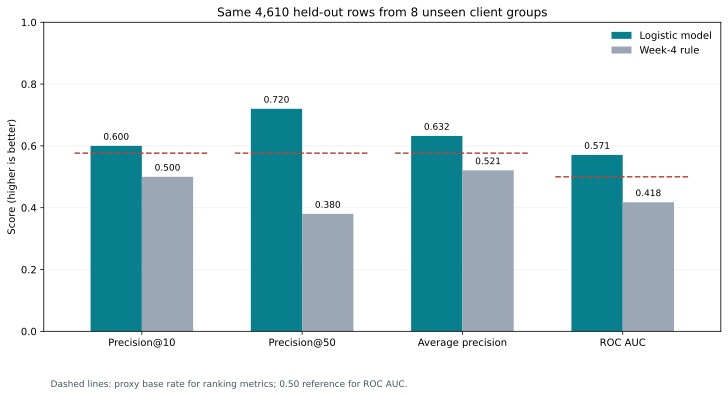

In [1]:
from pathlib import Path
import json, subprocess
import numpy as np, pandas as pd, sklearn, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
DATA_REL=Path("data/raw/content_refresh_anonymized.csv")
roots=[Path.cwd(),*Path.cwd().parents]
repo=next((r for r in roots if (r/DATA_REL).exists()),None)
if repo is None:
    repo=Path("/content/flyrank-ml-internship")
    if not (repo/DATA_REL).exists(): subprocess.run(["git","clone","--depth","1","https://github.com/Fiona-ali/flyrank-ml-internship.git",str(repo)],check=True)
out=repo/"work"; (out/"outputs").mkdir(parents=True,exist_ok=True); (out/"figures").mkdir(parents=True,exist_ok=True)
df=pd.read_csv(repo/DATA_REL)
assert df.shape==(30000,44),f"Unexpected starter extract: {df.shape}"
eligible=df.loc[pd.to_numeric(df.impressions_90d,errors="coerce")>=100].copy().reset_index(drop=True)
num=["search_volume","competition","cpc","word_count","char_count","content_age_days","days_since_last_update"]; cat=["content_type","main_intent"]; features=num+cat
forbidden={"content_id","client_id","trend_direction","trend_pct","is_declining_label","impressions_last_30d","impressions_prev_30d","clicks_last_30d","clicks_prev_30d","sessions_last_30d","sessions_prev_30d","impressions_90d","clicks_90d","pageviews_90d","sessions_90d","users_90d","engaged_sessions_90d","ai_sessions_90d","scroll_events_90d","ctr","avg_position","engagement_rate","scroll_rate","ai_traffic_pct"}
assert not(set(features)&forbidden)
X=eligible[features]; y=eligible.trend_direction.astype("string").str.lower().eq("down").astype(int).to_numpy(); groups=eligible.client_id.to_numpy()
tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=42).split(X,y,groups=groups))
assert set(groups[tr]).isdisjoint(set(groups[te]))
prep=ColumnTransformer([("num",Pipeline([("impute",SimpleImputer(strategy="median",add_indicator=True)),("scale",StandardScaler())]),num),("cat",Pipeline([("impute",SimpleImputer(strategy="constant",fill_value="__MISSING__")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat)])
model=Pipeline([("prep",prep),("model",LogisticRegression(max_iter=1000,random_state=42))]).fit(X.iloc[tr],y[tr]); ms=model.predict_proba(X.iloc[te])[:,1]
held=eligible.iloc[te]; rs=np.log1p(pd.to_numeric(held.impressions_90d,errors="coerce").clip(lower=0))*pd.to_numeric(held.days_since_last_update,errors="coerce").clip(lower=0,upper=180)/180
def summarize(s):
    order=np.argsort(-s,kind="mergesort"); yy=y[te][order]
    return {"precision_at_10":float(yy[:10].mean()),"precision_at_50":float(yy[:50].mean()),"average_precision":float(average_precision_score(y[te],s)),"roc_auc":float(roc_auc_score(y[te],s))}
base=float(y[te].mean())
metrics={"assignment":"ML-11 Capstone","lane":"Refresh / Content Opportunity Scoring","dataset":"Repository starter CSV; 30,000 anonymized content rows x 44 columns; 32 pseudonymous client groups","calendar_window":"Calendar dates unavailable; rolling metrics cover trailing 90 days and target compares latest 30 with preceding 30 days","eligibility":"impressions_90d >= 100","eligible_rows":len(eligible),"train_rows":len(tr),"test_rows":len(te),"train_clients":len(set(groups[tr])),"test_clients":len(set(groups[te])),"client_overlap":False,"test_proxy_base_rate":base,"target":"trend_direction == down; trailing-window proxy, not future outcome","features":features,"model":"Logistic Regression; numeric median imputation with missingness indicators and scaling; categorical explicit missing value and one-hot encoding; seed 42","model_metrics":summarize(ms),"week4_rule":"log1p(impressions_90d) * min(days_since_last_update,180) / 180; 90-day metric overlaps target windows","week4_rule_metrics":summarize(rs),"roc_auc_reference":0.5,"versions":{"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__}}
(out/"outputs/capstone_metrics.json").write_text(json.dumps(metrics,indent=2)+"\n")
prior=json.loads((out/"outputs/w07_action_playbook_metrics.json").read_text())
assert len(eligible)==22006 and len(tr)==17396 and len(te)==4610
assert abs(metrics["model_metrics"]["average_precision"]-prior["model_metrics"]["average_precision"])<1e-5
assert abs(metrics["model_metrics"]["roc_auc"]-prior["model_metrics"]["roc_auc"])<1e-5
labels=["Precision@10","Precision@50","Average precision","ROC AUC"]; keys=["precision_at_10","precision_at_50","average_precision","roc_auc"]
mv=[metrics["model_metrics"][k] for k in keys]; rv=[metrics["week4_rule_metrics"][k] for k in keys]; refs=[base,base,base,.5]
fig,ax=plt.subplots(figsize=(10,5.4),layout="constrained"); x=np.arange(4); w=.32
a=ax.bar(x-w/2,mv,w,label="Logistic model",color="#087f8c"); b=ax.bar(x+w/2,rv,w,label="Week-4 rule",color="#9ba7b4")
for i,z in enumerate(refs): ax.plot([i-.42,i+.42],[z,z],color="#b34837",ls="--",lw=1.5)
ax.set_ylim(0,1); ax.set_ylabel("Score (higher is better)"); ax.set_xticks(x,labels); ax.set_title("Same 4,610 held-out rows from 8 unseen client groups"); ax.grid(axis="y",alpha=.18); ax.set_axisbelow(True)
for bars in (a,b):
    for bar in bars: ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.02,f"{bar.get_height():.3f}",ha="center",fontsize=9)
ax.legend(frameon=False); ax.text(.01,-.18,"Dashed lines: proxy base rate for ranking metrics; 0.50 reference for ROC AUC.",transform=ax.transAxes,fontsize=9,color="#465665")
fig.savefig(out/"figures/capstone_model_vs_rule.svg",format="svg",bbox_inches="tight"); plt.show(); plt.close(fig)
print("PASS: client groups are disjoint; IDs, target, and performance-window fields are not model inputs.")
print(f"Eligible rows {len(eligible):,}; train/test rows {len(tr):,}/{len(te):,}; clients {len(set(groups[tr]))}/{len(set(groups[te]))}; test proxy base rate {base:.3f}.")
print("Metric                         Model     Week-4 rule")
for k,label in zip(keys,labels): print(f"{label:29s} {metrics['model_metrics'][k]:.3f}     {metrics['week4_rule_metrics'][k]:.3f}")
print("PASS: model metrics reproduce the committed Week-7 receipt.")
print("Saved work/outputs/capstone_metrics.json and work/figures/capstone_model_vs_rule.svg.")


## 5. Interpretation
On this one split, model Precision@50 is 0.720, 14.3 percentage points above the 0.577 proxy base rate and 34 points above the rule (0.380). Precision@10 is 0.600 versus 0.500 for the rule and 0.577 for base rate, a much smaller margin. Average precision is 0.632 versus 0.521; ROC AUC is 0.571 versus 0.418. This is a directional ranking improvement on this sample and proxy. Low ROC AUC and modest top-10 lift do not support strong prediction claims.

## 6. Limitations
The label is a trailing comparison, not a future outcome. One grouped split cannot show temporal or cross-client stability. Eligibility restricts the population. The baseline uses a metric overlapping the target windows. No experiment measured refresh impact, editorial time, or realized value. This starter extract does not support claims about the full warehouse or Google’s ranking system.

## 7. Ranked recommendations
1. Treat top 50 as a human-review starting list only.
2. Verify page intent and current state in the authorized internal system before any editorial change.
3. Before operational use, freeze a cutoff and define a non-overlapping future outcome; preserve client and time separation and compare against a simple baseline.
4. Record editor dispositions and future outcomes; proposed monitoring thresholds are not production-tested.

## 8. Reproducibility
Repository: https://github.com/Fiona-ali/flyrank-ml-internship

Model, validation, action-playbook, and capstone notebooks are in work/notebooks/. Metrics: work/outputs/capstone_metrics.json. Figure: work/figures/capstone_model_vs_rule.svg. Use the checked-in requirements.txt, open this notebook in Colab/Jupyter, and run all cells.

## 9. Acknowledgments and data credit
Built on the [FlyRank ML Internship dataset](https://flyrank.ai). The public analysis uses only the anonymized starter extract in Fiona’s repository; no private names, domains, URLs, query text, credentials, or raw ranked rows are included.

## ML-12 — Demo outline and shareable cuts

### Five-minute demo outline
0:00–0:35: state the editorial triage question. 0:35–1:15: show the anonymized starter extract, eligibility rule, and trailing proxy. 1:15–2:15: explain the nine fields and client-grouped 22/8 split. 2:15–3:30: compare rankings on 4,610 test rows; note base rate and modest top-10 margin. 3:30–4:20: show top-50 as a human-review queue. 4:20–5:00: explain the proxy limitation and propose a future-period evaluation.

### Social post draft
I compared a freshness-and-volume rule with a Logistic Regression review ranking on an anonymized FlyRank starter dataset. On one client-held-out split, the model reached 0.72 Precision@50 against a 0.58 trailing-window proxy base rate; the top-10 lift was much smaller, and this is not a future-outcome or causal test. I’m treating the ranking as a human-review aid and outlining a time-aware follow-up evaluation. Paper: https://fiona-ali.github.io/flyrank-capstone.html

### Employer-facing summary
I built a reproducible content-review ranking notebook and deployed a research paper for the Refresh / Content Opportunity Scoring lane. It uses a 30,000-row anonymized FlyRank starter extract and compares a logistic model with a transparent rule on a client-held-out split. The model reached 0.72 Precision@50 against 0.38 for the rule, but the target is a trailing-window proxy, so the output is limited to human-review prioritization pending future-period validation.

## Self-check
- [x] All nine paper sections, including abstract and linked data credit.
- [x] Model and comparator use the same grouped test rows.
- [x] IDs, label fields, and performance windows are excluded from model inputs.
- [x] Baseline overlap, one split, proxy target, and data scope disclosed.
- [x] Metrics checked against the existing Week-7 receipt.
- [x] ML-12 outline and two drafts included.